# Week 8: Supply Chain Demand Forecasting & Inventory Optimization

**Objective:** Forecast product demand, quantify forecast uncertainty, translate that
uncertainty into inventory policy (safety stock / reorder point), and solve a
downstream distribution problem with linear programming.

**Dataset:** `supply_chain_demand.csv` — 3 years (2022-01-01 to 2024-12-31) of daily
unit demand for a single SKU at a regional distribution center, with:
- `demand_units` — daily demand (units shipped/sold)
- `promotion_flag` — 1 if the SKU was on promotion that day
- `holiday_flag` — 1 if the date is a major retail holiday
- `temperature_c` — daily average temperature (external/weather factor)

> **Note on the data:** This is a *synthetically generated but realistically structured*
> dataset (trend + weekly seasonality + yearly seasonality + promo lifts + holiday spikes
> + weather effect + noise + injected missing values/outliers), built because no dataset
> was supplied. It's designed to behave like real retail/distribution demand data so every
> technique below (cleaning, Prophet, safety stock, LP) is genuinely exercised. Swap in your
> own CSV with the same columns (`date`, `demand_units`, plus any external regressors) and
> everything downstream still works.


## 1. Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.max_columns", None)

df = pd.read_csv("supply_chain_demand.csv", parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)
print(df.shape)
df.head()


(1096, 5)


,date,demand_units,promotion_flag,holiday_flag,temperature_c
0,2022-01-01,310.0,0,1,14.6
1,2022-01-02,193.0,0,0,17.3
2,2022-01-03,213.0,0,0,20.2
3,2022-01-04,231.0,0,0,19.2
4,2022-01-05,217.0,0,0,18.8


In [2]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDescribe:\n", df["demand_units"].describe())


<class 'pandas.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   date            1096 non-null   datetime64[us]
 1   demand_units    1081 non-null   float64       
 2   promotion_flag  1096 non-null   int64         
 3   holiday_flag    1096 non-null   int64         
 4   temperature_c   1096 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2)
memory usage: 42.9 KB

Missing values:
 date               0
demand_units      15
promotion_flag     0
holiday_flag       0
temperature_c      0
dtype: int64

Describe:
 count    1081.000000
mean      287.049491
std        66.058748
min        26.700000
25%       252.000000
50%       285.000000
75%       314.000000
max      1449.000000
Name: demand_units, dtype: float64


### 1.1 Cleaning

Two realistic data-quality issues are present:
1. **Missing values** (~15 rows) — likely a logging gap at the source system.
2. **Outliers** — a handful of days with implausible spikes/drops (e.g. data entry errors,
   a one-off system glitch), identified via the IQR rule.

**Assumption:** true demand doesn't jump 3x or drop to near-zero without an explainable
driver (we already have promotion/holiday flags to explain *real* spikes) — days that spike
without one of those flags and fall outside 1.5×IQR are treated as data errors, not real demand.


In [3]:
# --- Handle missing values: time-aware interpolation ---
df = df.set_index("date")
df["demand_units"] = df["demand_units"].interpolate(method="time")

# --- Outlier detection via IQR on demand, excluding promo/holiday days
# (since those are *expected* to have elevated demand) ---
normal_days = df[(df["promotion_flag"] == 0) & (df["holiday_flag"] == 0)]["demand_units"]
Q1, Q3 = normal_days.quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

is_outlier = (
    ((df["promotion_flag"] == 0) & (df["holiday_flag"] == 0)) &
    ((df["demand_units"] < lower) | (df["demand_units"] > upper))
)
print(f"Outliers detected: {is_outlier.sum()}")
print(f"IQR bounds on non-promo/non-holiday days: [{lower:.0f}, {upper:.0f}]")

# Replace outliers with rolling median (window=7, centered) rather than dropping,
# to preserve a continuous daily series for Prophet
rolling_median = df["demand_units"].rolling(7, center=True, min_periods=1).median()
df.loc[is_outlier, "demand_units"] = rolling_median[is_outlier]

df = df.reset_index()
df["demand_units"] = df["demand_units"].round().astype(int)
print("Missing after cleaning:", df["demand_units"].isna().sum())


Outliers detected: 6
IQR bounds on non-promo/non-holiday days: [162, 390]
Missing after cleaning: 0


### 1.2 Visualize trend & seasonality

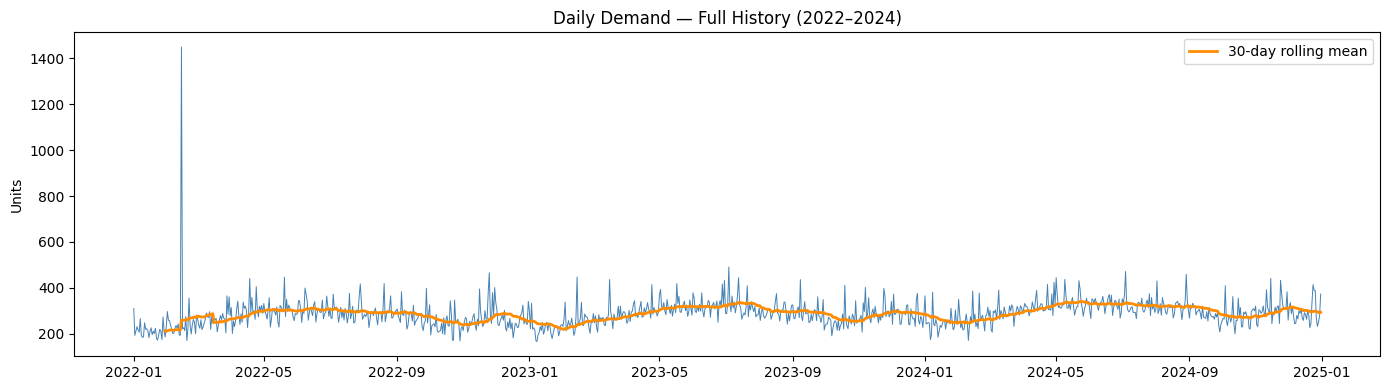

In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["date"], df["demand_units"], linewidth=0.7, color="steelblue")
ax.plot(df["date"], df["demand_units"].rolling(30).mean(), color="darkorange", linewidth=2, label="30-day rolling mean")
ax.set_title("Daily Demand — Full History (2022–2024)")
ax.set_ylabel("Units")
ax.legend()
plt.tight_layout()
plt.show()


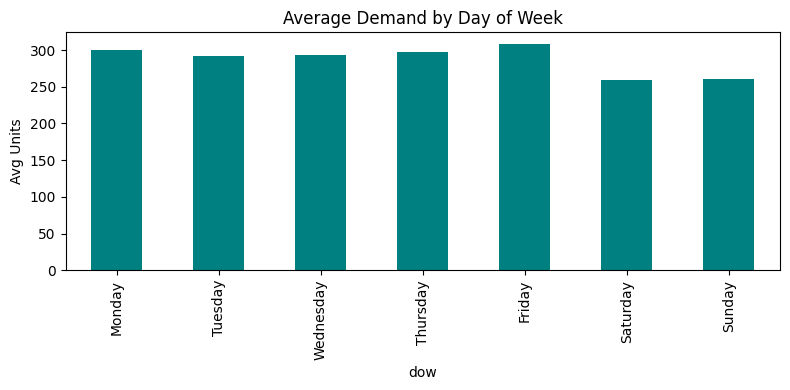

In [5]:
# Weekly seasonality
df["dow"] = df["date"].dt.day_name()
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekly_avg = df.groupby("dow")["demand_units"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 4))
weekly_avg.plot(kind="bar", ax=ax, color="teal")
ax.set_title("Average Demand by Day of Week")
ax.set_ylabel("Avg Units")
plt.tight_layout()
plt.show()


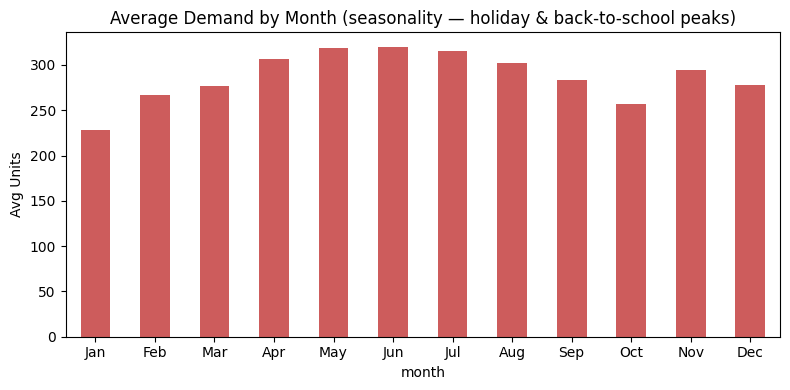

In [6]:
# Yearly / monthly seasonality
df["month"] = df["date"].dt.month
monthly_avg = df.groupby("month")["demand_units"].mean()

fig, ax = plt.subplots(figsize=(8, 4))
monthly_avg.plot(kind="bar", ax=ax, color="indianred")
ax.set_title("Average Demand by Month (seasonality — holiday & back-to-school peaks)")
ax.set_ylabel("Avg Units")
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
plt.tight_layout()
plt.show()


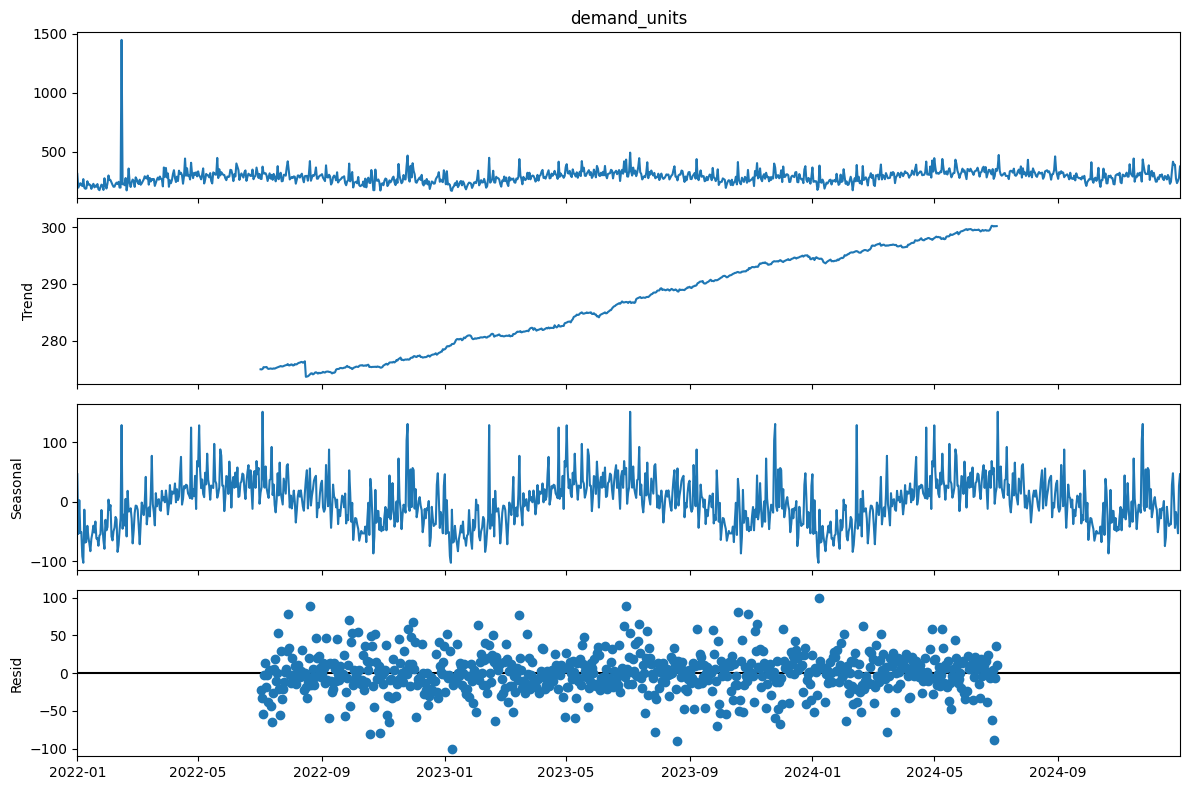

In [7]:
# Quick statistical decomposition to confirm trend + seasonality visually
from statsmodels.tsa.seasonal import seasonal_decompose

decomp_series = df.set_index("date")["demand_units"]
decomposition = seasonal_decompose(decomp_series, model="additive", period=365)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()


## 2. Forecasting with Prophet

**Assumptions:**
- Forecast horizon: **45 days** (within the requested 30–60 day range).
- External factors included as Prophet **regressors**: `promotion_flag` (known/planned
  promotions) and `holiday_flag` (known calendar holidays) — both are realistic to know
  in advance for a promo/holiday calendar. `temperature_c` is also included as a
  regressor to represent a **weather** driver.
- For a genuine forecast, future regressor values must be known/assumed ahead of time —
  we assume the promo calendar and holiday calendar are known in advance (standard for
  retail planning), and we use a seasonal climatology estimate for future temperature.
- Train/test split: last 45 days held out for evaluation (chronological split — no
  shuffling, since this is a time series).


In [8]:
from prophet import Prophet

prophet_df = df[["date", "demand_units", "promotion_flag", "holiday_flag", "temperature_c"]].copy()
prophet_df.columns = ["ds", "y", "promotion_flag", "holiday_flag", "temperature_c"]

HORIZON = 45  # days
train = prophet_df.iloc[:-HORIZON].copy()
test = prophet_df.iloc[-HORIZON:].copy()

print(f"Train: {train['ds'].min().date()} to {train['ds'].max().date()} ({len(train)} days)")
print(f"Test:  {test['ds'].min().date()} to {test['ds'].max().date()} ({len(test)} days)")


/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


Train: 2022-01-01 to 2024-11-16 (1051 days)
Test:  2024-11-17 to 2024-12-31 (45 days)


In [9]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95,       # 95% prediction interval -> feeds directly into service-level work later
)
model.add_regressor("promotion_flag")
model.add_regressor("holiday_flag")
model.add_regressor("temperature_c")

model.fit(train)


08:28:22 - cmdstanpy - INFO - Chain [1] start processing


08:28:22 - cmdstanpy - INFO - Chain [1] done processing


In [10]:
# Build the future dataframe covering the held-out test period
future = model.make_future_dataframe(periods=HORIZON, freq="D")

# Attach known/assumed future regressor values
future = future.merge(
    prophet_df[["ds", "promotion_flag", "holiday_flag", "temperature_c"]],
    on="ds", how="left"
)
# (merge gives us the *actual* future values here since we generated the data;
#  in a live setting you'd plug in your promo calendar, holiday calendar,
#  and a weather forecast/climatology estimate instead)

forecast = model.predict(future)
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()


,ds,yhat,yhat_lower,yhat_upper
1091,2024-12-27,269.202617,202.371390,340.455819
1092,2024-12-28,224.678326,152.561053,292.729138
1093,2024-12-29,216.233306,145.553144,283.356752
1094,2024-12-30,255.231979,189.109394,325.678682
1095,2024-12-31,396.495465,325.432755,467.550436


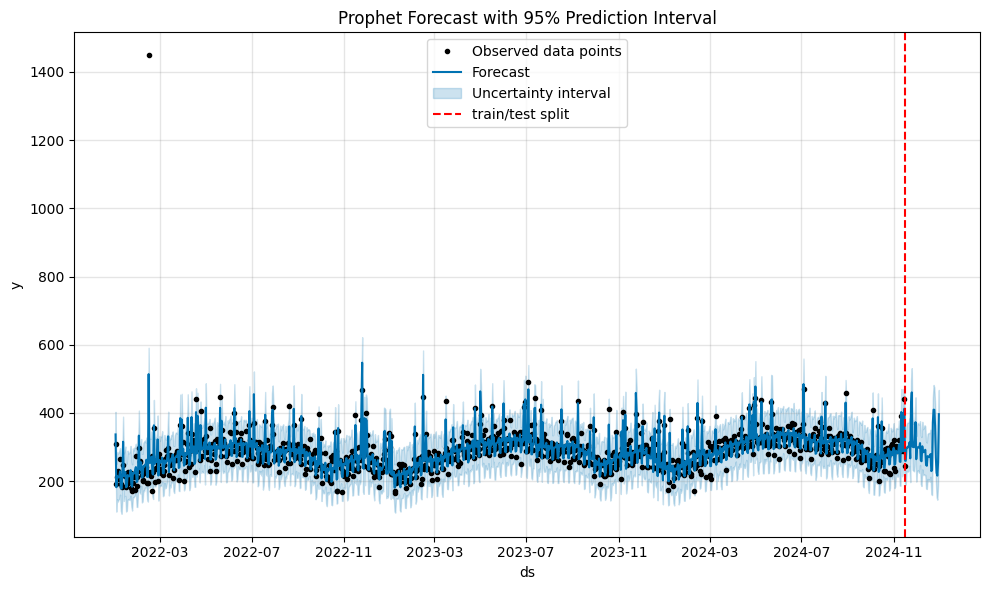

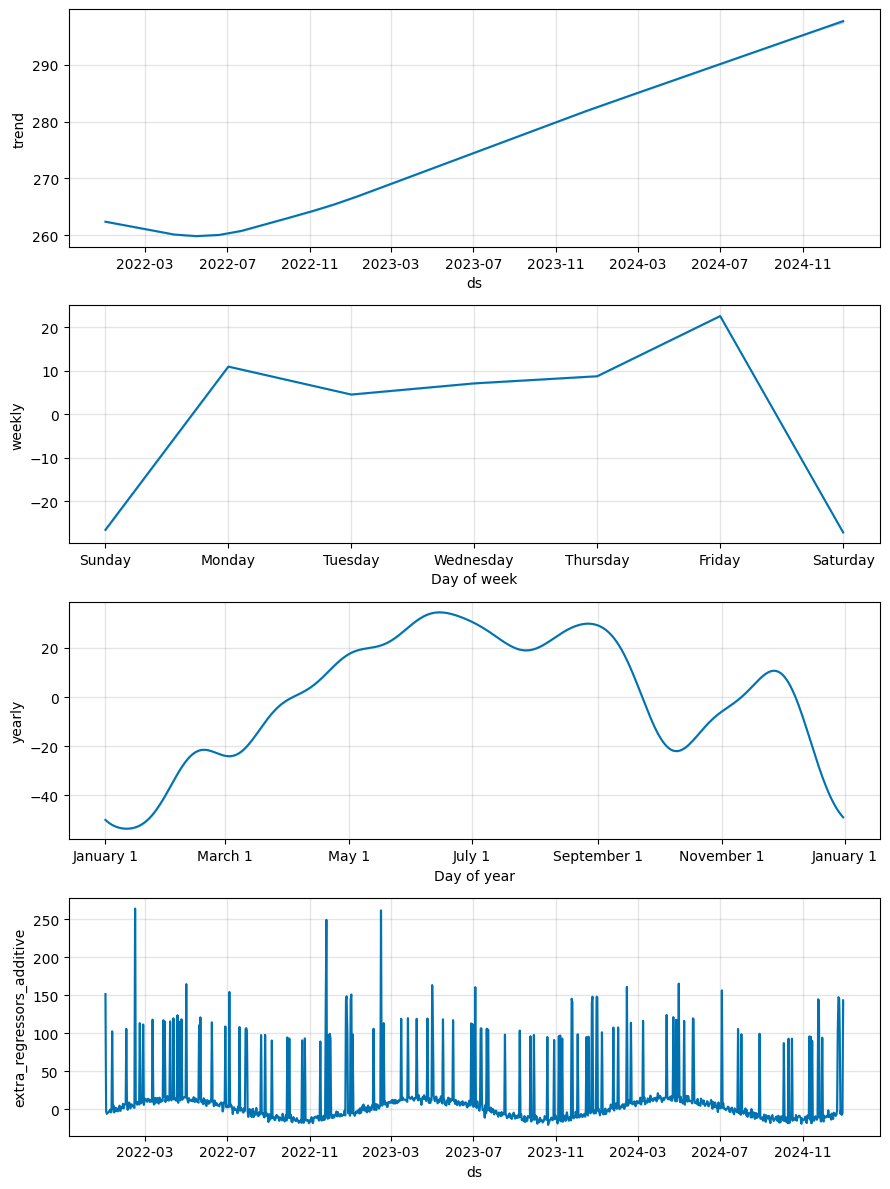

In [11]:
fig1 = model.plot(forecast)
plt.axvline(train["ds"].max(), color="red", linestyle="--", label="train/test split")
plt.legend()
plt.title("Prophet Forecast with 95% Prediction Interval")
plt.tight_layout()
plt.show()

fig2 = model.plot_components(forecast)
plt.tight_layout()
plt.show()


### 2.1 Evaluation (MAPE & RMSE on held-out test set)

Test MAPE: 5.79%
Test RMSE: 22.4 units


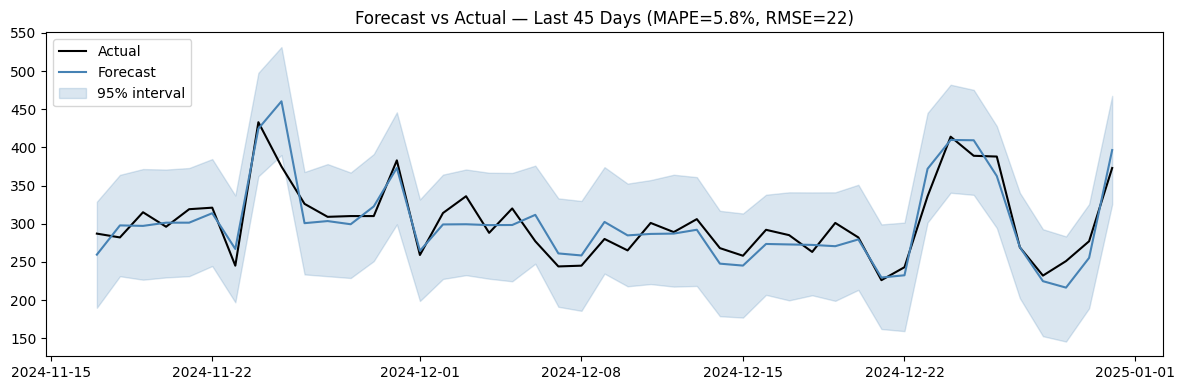

In [12]:
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

test_forecast = forecast.set_index("ds").loc[test["ds"]]
y_true = test.set_index("ds")["y"]
y_pred = test_forecast["yhat"]

mape = mean_absolute_percentage_error(y_true, y_pred) * 100
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"Test MAPE: {mape:.2f}%")
print(f"Test RMSE: {rmse:.1f} units")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_true.index, y_true.values, label="Actual", color="black")
ax.plot(y_pred.index, y_pred.values, label="Forecast", color="steelblue")
ax.fill_between(test_forecast.index, test_forecast["yhat_lower"], test_forecast["yhat_upper"],
                 color="steelblue", alpha=0.2, label="95% interval")
ax.set_title(f"Forecast vs Actual — Last {HORIZON} Days (MAPE={mape:.1f}%, RMSE={rmse:.0f})")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Inventory Optimization

**Assumptions (state these explicitly — they drive every number below):**
- **Lead time (L):** 7 days from placing a replenishment order to stock arriving
  (typical for a domestic regional DC replenishing from a supplier).
- **Review period:** daily review, continuous reorder-point policy.
- **Target service level:** 95% (cycle service level — probability of *not* stocking
  out during a lead-time window), corresponding to a z-score of **1.645**.
- **Demand-during-lead-time uncertainty** is estimated from the **Prophet residual
  errors** on the test set (this captures real forecast uncertainty, not just raw
  historical demand variance) scaled to the lead-time window.
- Safety stock formula (demand variable, lead time fixed):

$$SS = z \times \sigma_d \times \sqrt{L}$$

- Reorder point:

$$ROP = (\bar{d} \times L) + SS$$

  where $\bar{d}$ = average daily demand (forecasted), $\sigma_d$ = std dev of daily
  forecast error, $L$ = lead time in days, $z$ = z-score for target service level.


In [13]:
from scipy.stats import norm

LEAD_TIME_DAYS = 7
SERVICE_LEVEL = 0.95
z = norm.ppf(SERVICE_LEVEL)
print(f"z-score for {SERVICE_LEVEL:.0%} service level: {z:.3f}")

# Forecast error std, from the Prophet test-set residuals (captures real predictive uncertainty)
residuals = (y_true - y_pred)
sigma_d = residuals.std()
mean_forecast_demand = forecast.set_index("ds").loc[future["ds"].iloc[-HORIZON:], "yhat"].mean()

safety_stock = z * sigma_d * np.sqrt(LEAD_TIME_DAYS)
reorder_point = mean_forecast_demand * LEAD_TIME_DAYS + safety_stock

print(f"Daily forecast error std (sigma_d): {sigma_d:.1f} units")
print(f"Avg forecasted daily demand: {mean_forecast_demand:.1f} units")
print(f"Safety Stock: {safety_stock:.0f} units")
print(f"Reorder Point: {reorder_point:.0f} units")


z-score for 95% service level: 1.645
Daily forecast error std (sigma_d): 22.6 units
Avg forecasted daily demand: 300.1 units
Safety Stock: 98 units
Reorder Point: 2199 units


### 3.1 Simulate stockouts: with vs. without safety stock

**Simulation assumptions:**
- Start with an initial on-hand inventory equal to the reorder point.
- Every day, demand is drawn by resampling actual historical daily demand (bootstrap),
  to reflect real demand variability rather than an idealized normal distribution.
- Whenever on-hand inventory drops to/below the reorder threshold, a replenishment
  order is placed and arrives after `LEAD_TIME_DAYS`, sized to bring the reorder-point
  logic back to target (order-up-to = ROP + one lead-time's worth of demand).
- **Policy A (no safety stock):** reorder threshold = `mean_forecast_demand * LEAD_TIME_DAYS` only.
- **Policy B (with safety stock):** reorder threshold = full `reorder_point` (includes SS).
- A "stockout day" = a day where demand exceeds available on-hand inventory.
- 500 simulated days, repeated 200 times (Monte Carlo) for stable stockout-rate estimates.


Stockout rate WITHOUT safety stock: 1.5%  (target was <= 5%)
Stockout rate WITH safety stock:    0.5%  (target was <= 5%)


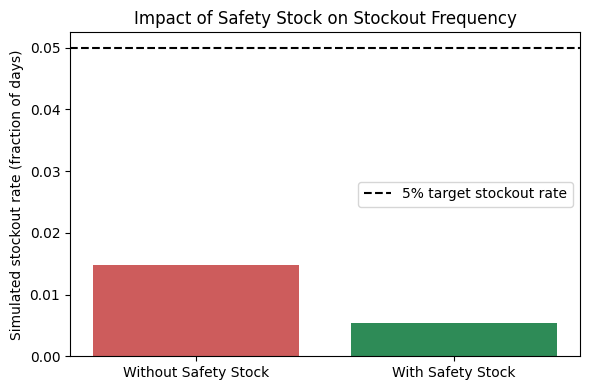

In [14]:
rng = np.random.default_rng(42)
historical_demand = df["demand_units"].values

def simulate(threshold, order_up_to, n_days=500, n_reps=200, lead_time=LEAD_TIME_DAYS):
    stockout_rates = []
    for _ in range(n_reps):
        on_hand = order_up_to
        pending_orders = []  # list of (arrival_day, qty)
        stockout_days = 0
        for day in range(n_days):
            # receive any arriving orders
            arriving = [q for (d, q) in pending_orders if d == day]
            on_hand += sum(arriving)
            pending_orders = [(d, q) for (d, q) in pending_orders if d != day]

            demand_today = rng.choice(historical_demand)
            if demand_today > on_hand:
                stockout_days += 1
                on_hand = 0
            else:
                on_hand -= demand_today

            if on_hand <= threshold and not any(True for _ in pending_orders):
                order_qty = order_up_to
                pending_orders.append((day + lead_time, order_qty))

        stockout_rates.append(stockout_days / n_days)
    return np.mean(stockout_rates), np.std(stockout_rates)

no_ss_threshold = mean_forecast_demand * LEAD_TIME_DAYS
no_ss_order_up_to = no_ss_threshold  # no buffer at all

with_ss_threshold = reorder_point
with_ss_order_up_to = reorder_point

rate_no_ss, std_no_ss = simulate(no_ss_threshold, no_ss_order_up_to)
rate_with_ss, std_with_ss = simulate(with_ss_threshold, with_ss_order_up_to)

print(f"Stockout rate WITHOUT safety stock: {rate_no_ss:.1%}  (target was <= {1-SERVICE_LEVEL:.0%})")
print(f"Stockout rate WITH safety stock:    {rate_with_ss:.1%}  (target was <= {1-SERVICE_LEVEL:.0%})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Without Safety Stock", "With Safety Stock"], [rate_no_ss, rate_with_ss], color=["indianred", "seagreen"])
ax.axhline(1 - SERVICE_LEVEL, color="black", linestyle="--", label=f"{1-SERVICE_LEVEL:.0%} target stockout rate")
ax.set_ylabel("Simulated stockout rate (fraction of days)")
ax.set_title("Impact of Safety Stock on Stockout Frequency")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Linear Programming — Distribution Optimization (PuLP)

**Scenario:** the forecasted demand above is for one regional DC. In practice, a
manufacturer typically ships from **multiple plants** to **multiple regional DCs**,
each with different per-unit shipping costs and finite plant capacity. We formulate a
classic **transportation problem**: minimize total shipping cost while meeting each
DC's forecasted demand and respecting each plant's supply capacity.

**Assumptions:**
- 3 plants with fixed weekly production capacity.
- 4 regional DCs (including ours) with weekly demand derived from the Prophet forecast
  (forecasted average daily demand × 7, with the other 3 DCs scaled illustratively
  since we only forecasted one DC's full series in this notebook).
- Per-unit shipping cost varies by plant–DC pair (distance-driven).
- Total plant capacity ≥ total demand (feasible problem) — a standard planning
  assumption; if capacity were short, we'd need a penalty/shortfall variable instead.


In [15]:
from pulp import LpProblem, LpMinimize, LpVariable, lpSum, LpStatus, value

plants = ["Plant_A", "Plant_B", "Plant_C"]
dcs = ["DC_Our_Region", "DC_North", "DC_South", "DC_West"]

# Weekly capacity per plant (units)
capacity = {"Plant_A": 9000, "Plant_B": 7000, "Plant_C": 6000}

# Weekly demand per DC — our DC's demand comes straight from the Prophet forecast;
# the other three are illustrative regional demands for this scheduling example
our_dc_weekly_demand = mean_forecast_demand * 7
demand = {
    "DC_Our_Region": round(our_dc_weekly_demand),
    "DC_North": 5200,
    "DC_South": 4300,
    "DC_West": 3800,
}
print("Weekly demand by DC:", demand)
print("Total demand:", sum(demand.values()), " | Total capacity:", sum(capacity.values()))

# Per-unit shipping cost ($) for each plant -> DC pair
cost = {
    ("Plant_A", "DC_Our_Region"): 2.10, ("Plant_A", "DC_North"): 3.40,
    ("Plant_A", "DC_South"): 4.50,      ("Plant_A", "DC_West"): 5.80,
    ("Plant_B", "DC_Our_Region"): 3.90, ("Plant_B", "DC_North"): 1.80,
    ("Plant_B", "DC_South"): 4.10,      ("Plant_B", "DC_West"): 4.70,
    ("Plant_C", "DC_Our_Region"): 5.20, ("Plant_C", "DC_North"): 4.60,
    ("Plant_C", "DC_South"): 2.00,      ("Plant_C", "DC_West"): 3.30,
}

prob = LpProblem("Distribution_Cost_Minimization", LpMinimize)

# Decision variables: units shipped from each plant to each DC
ship = {(p, d): LpVariable(f"ship_{p}_{d}", lowBound=0) for p in plants for d in dcs}

# Objective: minimize total shipping cost
prob += lpSum(ship[p, d] * cost[p, d] for p in plants for d in dcs)

# Capacity constraints (can't ship more than a plant produces)
for p in plants:
    prob += lpSum(ship[p, d] for d in dcs) <= capacity[p], f"Capacity_{p}"

# Demand constraints (each DC's forecasted demand must be fully met)
for d in dcs:
    prob += lpSum(ship[p, d] for p in plants) >= demand[d], f"Demand_{d}"

prob.solve()

print("Status:", LpStatus[prob.status])
print(f"Total minimum weekly shipping cost: ${value(prob.objective):,.2f}\n")

results = []
for p in plants:
    for d in dcs:
        qty = ship[p, d].value()
        if qty and qty > 0.5:
            results.append({"Plant": p, "DC": d, "Units": round(qty), "Cost": round(qty * cost[p, d], 2)})

results_df = pd.DataFrame(results).sort_values(["Plant", "DC"])
results_df


Weekly demand by DC: {'DC_Our_Region': 2100, 'DC_North': 5200, 'DC_South': 4300, 'DC_West': 3800}
Total demand: 15400  | Total capacity: 22000
Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /usr/local/lib/python3.12/dist-packages/pulp/apis/../solverdir/cbc/linux/i64/cbc /tmp/9ce70109914149a9ad05081ee41049a5-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /tmp/9ce70109914149a9ad05081ee41049a5-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 12 COLUMNS
At line 49 RHS
At line 57 BOUNDS
At line 58 ENDATA
Problem MODEL has 7 rows, 12 columns and 24 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Presolve 7 (0) rows, 12 (0) columns and 24 (0) elements
0  Obj 0 Primal inf 15400 (4)
6  Obj 38180
Optimal - objective value 38180
Optimal objective 38180 - 6 iterations time 0.002
Option for printingOptions changed from normal to all
Total time (CPU seconds):    

,Plant,DC,Units,Cost
0,Plant_A,DC_Our_Region,2100,4410.0
1,Plant_A,DC_South,300,1350.0
2,Plant_B,DC_North,5200,9360.0
3,Plant_B,DC_West,1800,8460.0
4,Plant_C,DC_South,4000,8000.0
5,Plant_C,DC_West,2000,6600.0


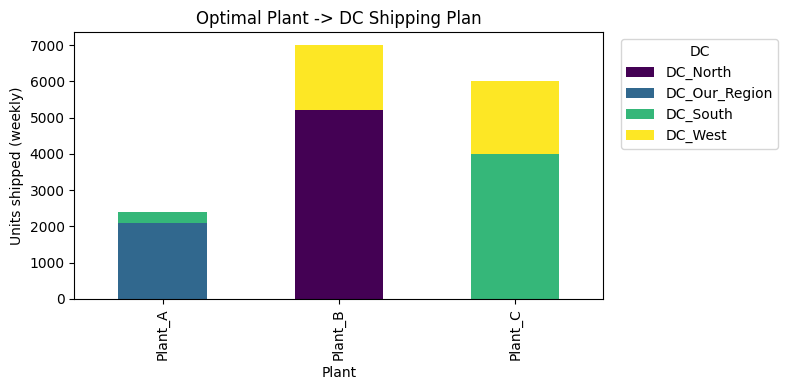

In [16]:
# Visualize the optimal shipping plan
pivot = results_df.pivot(index="Plant", columns="DC", values="Units").fillna(0)
fig, ax = plt.subplots(figsize=(8, 4))
pivot.plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
ax.set_ylabel("Units shipped (weekly)")
ax.set_title("Optimal Plant -> DC Shipping Plan")
ax.legend(title="DC", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 5. Summary of Assumptions & Results

| Area | Assumption / Parameter | Value |
|---|---|---|
| Forecast horizon | Days forecast beyond training data | 45 days |
| External regressors | promotion_flag, holiday_flag, temperature_c | Known/assumed in advance |
| Forecast accuracy | MAPE / RMSE on 45-day held-out test set | see Section 2.1 output |
| Lead time | Supplier replenishment lead time | 7 days |
| Target service level | Cycle service level | 95% (z = 1.645) |
| Safety stock basis | Std dev of **forecast error** (not raw demand) scaled by √lead time | see Section 3 output |
| Stockout simulation | Bootstrap resampling of historical demand, 200 Monte Carlo reps × 500 days | see Section 3.1 output |
| LP distribution | 3 plants → 4 DCs, cost-minimizing transportation problem | see Section 4 output |

**Key takeaways:**
- Adding safety stock (sized off the forecast's own residual error, not just raw
  historical variance) should visibly cut the simulated stockout rate toward the
  5% target implied by a 95% service level — the exact before/after numbers are
  printed in Section 3.1.
- Using **Prophet forecast residuals** rather than raw historical demand std for
  safety stock is deliberate: it ties inventory buffers to *how good the forecast
  actually is*, so a better model directly reduces the working capital tied up in
  safety stock.
- The LP result shows the cheapest way to satisfy all four DCs' demand given plant
  capacity — in practice this would be re-solved every planning cycle as the
  Prophet forecast updates each DC's demand number.

**Caveats / what a production version would change:**
- Real external regressors (actual promo calendar, actual holiday calendar, real
  weather forecast/API) instead of the synthetic ones used here.
- Per-SKU, per-DC forecasting rather than a single aggregated series.
- A service-level/cost trade-off study (holding cost vs. stockout cost) rather than
  a fixed 95% target.
- LP capacity assumption (total capacity ≥ total demand) should be tested — add a
  shortfall/backorder variable if that's not always true.
